# Text wrangling and cleaning (pre-processing)



In [1]:
import html
import re
from locale import normalize

import pandas as pd
import numpy as np
from IPython.core.pylabtools import figsize

# read a dataset with 100 papers

hcai_paper = pd.read_csv("/Users/jieswang/PycharmProjects/Human_centered_AI_in_papers_and_patents/data/00-open_alex_datasets/hcai_paper_dataset_dropped_duplicates_2026-10-12_15-12-22.csv").sort_values(by='citations', ascending=False).head(100)

In [6]:
hcai_paper.dtypes

id               str
doi              str
title            str
year         float64
citations      int64
authors          str
topic            str
keywords         str
abstract         str
type             str
dtype: object

In [2]:
# inspect abstract
for index, row in hcai_paper.sample(3).iterrows():
    print("\n------ Separator ------")
    print(f"Title: {row['title']}")
    print(f"Author: {row['authors']}")
    print(f"Abstract: {row['abstract']}")


------ Separator ------
Title: What Is Qualitative Research? An Overview and Guidelines
Author: ['Weng Marc Lim']
Abstract: This guide explains the focus, rigor, and relevance of qualitative research, highlighting its role in dissecting complex social phenomena and providing in-depth, human-centered insights. The guide also examines the rationale for employing qualitative methods, underscoring their critical importance. An exploration of the methodology’s strengths, such as its ability to offer contextual depth and holistic perspectives, is juxtaposed against challenges like constrained generalizability and potential researcher bias, accompanied by practical mitigation strategies. Covering a spectrum of qualitative approaches, including grounded theory, phenomenology, ethnography, action research, and general inquiry, the guide sheds light on diverse data collection and analysis techniques. Noteworthily, the guide underscores the crucial aspect of trustworthiness in qualitative resear

## Cleaning text
Let's clean the title firsts, and they are shorter.

In [3]:

def clean(text: str):
    # convert html escapes like &amp; to characters.
    text = html.unescape(text)
    # tags like <tab>
    text = re.sub(r'<[^<>]*>', ' ', text)
    # markdown URLs like [Some text](https://....)
    text = re.sub(r'\[([^\[\]]*)\]\([^\(\)]*\)', r'\1', text)
    # text or code in brackets like [0]
    text = re.sub(r'\[[^\[\]]*\]', ' ', text)
    # standalone sequences of specials, matches &# but not #cool
    text = re.sub(r'(?:^|\s)[&#<>{}\[\]+|\\:-]{1,}(?:\s|$)', ' ', text)
    # standalone sequences of hyphens like --- or ==
    text = re.sub(r'(?:^|\s)[\-=\+]{2,}(?:\s|$)', ' ', text)
    # sequences of white spaces
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

hcai_paper['title_cleaned'] = hcai_paper['title'].apply(clean).str.lower()

In [4]:
hcai_paper[['title','title_cleaned']]

,title,title_cleaned
7108,Causability and explainability of artificial i...,causability and explainability of artificial i...
7170,Industry 5.0—A Human-Centric Solution,industry 5.0—a human-centric solution
7047,Human-Centered Artificial Intelligence: Reliab...,human-centered artificial intelligence: reliab...
5942,What Is Qualitative Research? An Overview and ...,what is qualitative research? an overview and ...
6509,Practical and ethical challenges of large lang...,practical and ethical challenges of large lang...
...,...,...
6787,Smooth and Resilient Human–Machine Teamwork as...,smooth and resilient human–machine teamwork as...
7072,Geometry Guided Pose-Invariant Facial Expressi...,geometry guided pose-invariant facial expressi...
6753,Human-Centered Artificial Intelligence: The Su...,human-centered artificial intelligence: the su...
6679,Utopia versus dystopia: Professional perspecti...,utopia versus dystopia: professional perspecti...


## Sentence splitter

In [5]:
from nltk.tokenize import sent_tokenize

random_abstract = hcai_paper.sample(1).iloc[0]['abstract']
print(random_abstract)

BACKGROUND: Alongside the promise of improving clinical work, advances in healthcare artificial intelligence (AI) raise concerns about the risk of deskilling clinicians. This purpose of this study is to examine the issue of deskilling from the perspective of diverse group of professional stakeholders with knowledge and/or experiences in the development, deployment and regulation of healthcare AI. METHODS: We conducted qualitative, semi-structured interviews with 72 professionals with AI expertise and/or professional or clinical expertise who were involved in development, deployment and/or regulation of healthcare AI. Data analysis using combined constructivist grounded theory and framework approach was performed concurrently with data collection. FINDINGS: Our analysis showed participants had diverse views on three contentious issues regarding AI and deskilling. The first involved competing views about the proper extent of AI-enabled automation in healthcare work, and which clinical ta

In [6]:
all_sent = sent_tokenize(random_abstract)
print(len(all_sent))
print(all_sent)

12
['BACKGROUND: Alongside the promise of improving clinical work, advances in healthcare artificial intelligence (AI) raise concerns about the risk of deskilling clinicians.', 'This purpose of this study is to examine the issue of deskilling from the perspective of diverse group of professional stakeholders with knowledge and/or experiences in the development, deployment and regulation of healthcare AI.', 'METHODS: We conducted qualitative, semi-structured interviews with 72 professionals with AI expertise and/or professional or clinical expertise who were involved in development, deployment and/or regulation of healthcare AI.', 'Data analysis using combined constructivist grounded theory and framework approach was performed concurrently with data collection.', 'FINDINGS: Our analysis showed participants had diverse views on three contentious issues regarding AI and deskilling.', 'The first involved competing views about the proper extent of AI-enabled automation in healthcare work, a

## Normalization
Text normalization is the process of transforming raw text into a single, standardized canonical form so that downstream systems can process it consistently

In [7]:
import textacy.preprocessing as tprep

normalize = tprep.make_pipeline(
    tprep.normalize.hyphenated_words,
    tprep.normalize.quotation_marks,
    tprep.normalize.unicode,
    tprep.remove.accents,
    tprep.remove.punctuation,
    tprep.normalize.whitespace
)

hcai_paper['title_normalized'] = hcai_paper['title_cleaned'].apply(normalize)

In [8]:
display(hcai_paper[['title','title_cleaned','title_normalized']])

,title,title_cleaned,title_normalized
7108,Causability and explainability of artificial i...,causability and explainability of artificial i...,causability and explainability of artificial i...
7170,Industry 5.0—A Human-Centric Solution,industry 5.0—a human-centric solution,industry 5 0 a human centric solution
7047,Human-Centered Artificial Intelligence: Reliab...,human-centered artificial intelligence: reliab...,human centered artificial intelligence reliabl...
5942,What Is Qualitative Research? An Overview and ...,what is qualitative research? an overview and ...,what is qualitative research an overview and g...
6509,Practical and ethical challenges of large lang...,practical and ethical challenges of large lang...,practical and ethical challenges of large lang...
...,...,...,...
6787,Smooth and Resilient Human–Machine Teamwork as...,smooth and resilient human–machine teamwork as...,smooth and resilient human machine teamwork as...
7072,Geometry Guided Pose-Invariant Facial Expressi...,geometry guided pose-invariant facial expressi...,geometry guided pose invariant facial expressi...
6753,Human-Centered Artificial Intelligence: The Su...,human-centered artificial intelligence: the su...,human centered artificial intelligence the sup...
6679,Utopia versus dystopia: Professional perspecti...,utopia versus dystopia: professional perspecti...,utopia versus dystopia professional perspectiv...


## Tokenization

In [9]:
# Using Python string split function
s = ("Hello everyone !\n\nWelcome to EST 610 !")
s.split()

['Hello', 'everyone', '!', 'Welcome', 'to', 'EST', '610', '!']

In [10]:
# Using nltk tokeniers
from nltk import word_tokenize
from nltk.tokenize import regexp_tokenize, wordpunct_tokenize, blankline_tokenize

print("nltk.word_tokenize:", word_tokenize(s))
print("regexp_tokenize (words):", regexp_tokenize(s, pattern=r'\w+')) # \w+ matches sequences of word characters, ignoring spaces and most punctuation.
print("regexp_tokenize (digits):", regexp_tokenize(s, pattern=r'\d+'))
print("wordpunct tokenizer:", wordpunct_tokenize(s))
print("bankline tokenizer", blankline_tokenize(s)) # splits a text into paragraphs based on blank lines (\n\n)

nltk.word_tokenize: ['Hello', 'everyone', '!', 'Welcome', 'to', 'EST', '610', '!']
regexp_tokenize (words): ['Hello', 'everyone', 'Welcome', 'to', 'EST', '610']
regexp_tokenize (digits): ['610']
wordpunct tokenizer: ['Hello', 'everyone', '!', 'Welcome', 'to', 'EST', '610', '!']
bankline tokenizer ['Hello everyone !', 'Welcome to EST 610 !']


In [11]:
# Let's try tokenize our titles in the paper dataset
hcai_paper['title_tokenized'] = hcai_paper['title_normalized'].apply(word_tokenize)

display(hcai_paper[['title','title_tokenized']])

,title,title_tokenized
7108,Causability and explainability of artificial i...,"[causability, and, explainability, of, artific..."
7170,Industry 5.0—A Human-Centric Solution,"[industry, 5, 0, a, human, centric, solution]"
7047,Human-Centered Artificial Intelligence: Reliab...,"[human, centered, artificial, intelligence, re..."
5942,What Is Qualitative Research? An Overview and ...,"[what, is, qualitative, research, an, overview..."
6509,Practical and ethical challenges of large lang...,"[practical, and, ethical, challenges, of, larg..."
...,...,...
6787,Smooth and Resilient Human–Machine Teamwork as...,"[smooth, and, resilient, human, machine, teamw..."
7072,Geometry Guided Pose-Invariant Facial Expressi...,"[geometry, guided, pose, invariant, facial, ex..."
6753,Human-Centered Artificial Intelligence: The Su...,"[human, centered, artificial, intelligence, th..."
6679,Utopia versus dystopia: Professional perspecti...,"[utopia, versus, dystopia, professional, persp..."


## Multiword Expression (MWE) detection
(after tokenization, but before lemmatization and remove stop words)

In [12]:
from nltk.tokenize import MWETokenizer

random_abstract='Deep learning has exploded in the public consciousness, primarily as predictive and analytical products suffuse our world, in the form of numerous human-centered smart-world systems, including targeted advertisements, natural language assistants and interpreters, and prototype self-driving vehicle systems. Yet to most, the underlying mechanisms that enable such human-centered smart products remain obscure. In contrast, researchers across disciplines have been incorporating deep learning into their research to solve problems that could not have been approached before. In this paper, we seek to provide a thorough investigation of deep learning in its applications and mechanisms. Specifically, as a categorical collection of state of the art in deep learning research, we hope to provide a broad reference for those seeking a primer on deep learning and its various implementations, platforms, algorithms, and uses in a variety of smart-world systems. Furthermore, we hope to outline recent key advancements in the technology, and provide insight into areas, in which deep learning can improve investigation, as well as highlight new areas of research that have yet to see the application of deep learning, but could nonetheless benefit immensely. We hope this survey provides a valuable reference for new deep learning practitioners, as well as those seeking to innovate in the application of deep learning.'

tokenized_abstract = [i.lower() for i in word_tokenize(normalize(clean(random_abstract)))]

print(tokenized_abstract)

['deep', 'learning', 'has', 'exploded', 'in', 'the', 'public', 'consciousness', 'primarily', 'as', 'predictive', 'and', 'analytical', 'products', 'suffuse', 'our', 'world', 'in', 'the', 'form', 'of', 'numerous', 'human', 'centered', 'smart', 'world', 'systems', 'including', 'targeted', 'advertisements', 'natural', 'language', 'assistants', 'and', 'interpreters', 'and', 'prototype', 'self', 'driving', 'vehicle', 'systems', 'yet', 'to', 'most', 'the', 'underlying', 'mechanisms', 'that', 'enable', 'such', 'human', 'centered', 'smart', 'products', 'remain', 'obscure', 'in', 'contrast', 'researchers', 'across', 'disciplines', 'have', 'been', 'incorporating', 'deep', 'learning', 'into', 'their', 'research', 'to', 'solve', 'problems', 'that', 'could', 'not', 'have', 'been', 'approached', 'before', 'in', 'this', 'paper', 'we', 'seek', 'to', 'provide', 'a', 'thorough', 'investigation', 'of', 'deep', 'learning', 'in', 'its', 'applications', 'and', 'mechanisms', 'specifically', 'as', 'a', 'catego

In [13]:
# based on your understanding of the corpus, create a list of MWEs that you would like them to stay together

mwes = ['deep learning', 'human centered', 'artificial intelligence']

multi_words_list = [tuple(i.lower().split()) for i in mwes]

multi_words_tokenizer = MWETokenizer(multi_words_list).tokenize

In [14]:
mwe_tokeonized_abstract = multi_words_tokenizer(tokenized_abstract)

print(mwe_tokeonized_abstract)

['deep_learning', 'has', 'exploded', 'in', 'the', 'public', 'consciousness', 'primarily', 'as', 'predictive', 'and', 'analytical', 'products', 'suffuse', 'our', 'world', 'in', 'the', 'form', 'of', 'numerous', 'human_centered', 'smart', 'world', 'systems', 'including', 'targeted', 'advertisements', 'natural', 'language', 'assistants', 'and', 'interpreters', 'and', 'prototype', 'self', 'driving', 'vehicle', 'systems', 'yet', 'to', 'most', 'the', 'underlying', 'mechanisms', 'that', 'enable', 'such', 'human_centered', 'smart', 'products', 'remain', 'obscure', 'in', 'contrast', 'researchers', 'across', 'disciplines', 'have', 'been', 'incorporating', 'deep_learning', 'into', 'their', 'research', 'to', 'solve', 'problems', 'that', 'could', 'not', 'have', 'been', 'approached', 'before', 'in', 'this', 'paper', 'we', 'seek', 'to', 'provide', 'a', 'thorough', 'investigation', 'of', 'deep_learning', 'in', 'its', 'applications', 'and', 'mechanisms', 'specifically', 'as', 'a', 'categorical', 'collec

## Stemming
(After tokenization)
Stemming is the process of reducing inflected (or something derived) words to their word stem, base or root form, e.g., cats to cat, fishing and fisher to fish, arguing to argu.

In [15]:
from nltk.stem import PorterStemmer # import Porter stemmer
from nltk.stem.lancaster import LancasterStemmer
from nltk.stem import SnowballStemmer

pst = PorterStemmer()   # create obj of the PorterStemmer
lst = LancasterStemmer() # create obj of LancasterStemmer
lst.stem("eating")

'eat'

In [44]:

pst.stem("shopping")


'shop'

## Lemmatization
(also after tokenization)
the process of grouping together the inflected forms of a word so they can be analysed as a single item, identified by the word's lemma, or dictionary form.


In [16]:
from nltk.stem import WordNetLemmatizer
wlem = WordNetLemmatizer()

# pos='v' to tell NLTK that the word is a verb:
wlem.lemmatize("ate", pos='v')


'eat'

In [17]:
print("lemmatize 'better' as a noun:", wlem.lemmatize("better", pos='n'))
print("lemmatize 'better' as a adjective:", wlem.lemmatize("better", pos='a'))

lemmatize 'better' as a noun: better
lemmatize 'better' as a adjective: good


In [18]:
# lemmatize the tokeinzed title column
hcai_paper['title_lemmatized'] = hcai_paper['title_tokenized'].apply(
    lambda tokens: [wlem.lemmatize(word) for word in tokens]
)

display(hcai_paper[['title_tokenized','title_lemmatized']])

,title_tokenized,title_lemmatized
7108,"[causability, and, explainability, of, artific...","[causability, and, explainability, of, artific..."
7170,"[industry, 5, 0, a, human, centric, solution]","[industry, 5, 0, a, human, centric, solution]"
7047,"[human, centered, artificial, intelligence, re...","[human, centered, artificial, intelligence, re..."
5942,"[what, is, qualitative, research, an, overview...","[what, is, qualitative, research, an, overview..."
6509,"[practical, and, ethical, challenges, of, larg...","[practical, and, ethical, challenge, of, large..."
...,...,...
6787,"[smooth, and, resilient, human, machine, teamw...","[smooth, and, resilient, human, machine, teamw..."
7072,"[geometry, guided, pose, invariant, facial, ex...","[geometry, guided, pose, invariant, facial, ex..."
6753,"[human, centered, artificial, intelligence, th...","[human, centered, artificial, intelligence, th..."
6679,"[utopia, versus, dystopia, professional, persp...","[utopia, versus, dystopia, professional, persp..."


- As you may have noticed, it seems the lemmatization did not do much work, because it assumes every word is a noun.
- One additional process is to specify the part of speech (POS)

In [19]:
words = ['cats', 'running', 'ate', 'better']

# Without POS tagging
[wlem.lemmatize(word) for word in words]

['cat', 'running', 'ate', 'better']

In [20]:
print(wlem.lemmatize('cats', pos='n'))
print(wlem.lemmatize('running', pos='v'))
print(wlem.lemmatize('ate', pos='v'))
print(wlem.lemmatize('better', pos='a'))

cat
run
eat
good


In [21]:
# to improve our lemmatization for dataframes
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from typing import Optional

def lemmatize(tokens: Optional[list]) -> Optional[list]:
    if tokens is None:
        return None

    lemmatizer = WordNetLemmatizer()

    # POS tagging
    pos_tags = pos_tag(tokens)

    # Map NLTK POS tags to WordNet POS tags
    wn_tags = {"N": wordnet.NOUN, "V": wordnet.VERB,
               "R": wordnet.ADV, "J": wordnet.ADJ}

    # Lemmatize tokens based on POS tags
    lemmatized_tokens = [
        lemmatizer.lemmatize(token, wn_tags.get(pos[0], wordnet.NOUN))
        for token, pos in pos_tags
    ]

    return lemmatized_tokens

a_sentence = 'The cats are running and they ate fish.'
print("Tokenize:", tokenized_sentence_a:=word_tokenize(a_sentence))
print("Lemmatize: ", lemmatize(tokenized_sentence_a))

Tokenize: ['The', 'cats', 'are', 'running', 'and', 'they', 'ate', 'fish', '.']
Lemmatize:  ['The', 'cat', 'be', 'run', 'and', 'they', 'eat', 'fish', '.']


In [22]:
hcai_paper['title_lemmatized_pos'] = hcai_paper['title_tokenized'].apply(lemmatize)

display(hcai_paper[['title_tokenized','title_lemmatized_pos']])

,title_tokenized,title_lemmatized_pos
7108,"[causability, and, explainability, of, artific...","[causability, and, explainability, of, artific..."
7170,"[industry, 5, 0, a, human, centric, solution]","[industry, 5, 0, a, human, centric, solution]"
7047,"[human, centered, artificial, intelligence, re...","[human, center, artificial, intelligence, reli..."
5942,"[what, is, qualitative, research, an, overview...","[what, be, qualitative, research, an, overview..."
6509,"[practical, and, ethical, challenges, of, larg...","[practical, and, ethical, challenge, of, large..."
...,...,...
6787,"[smooth, and, resilient, human, machine, teamw...","[smooth, and, resilient, human, machine, teamw..."
7072,"[geometry, guided, pose, invariant, facial, ex...","[geometry, guide, pose, invariant, facial, exp..."
6753,"[human, centered, artificial, intelligence, th...","[human, center, artificial, intelligence, the,..."
6679,"[utopia, versus, dystopia, professional, persp...","[utopia, versus, dystopia, professional, persp..."


## Remove stop words


In [23]:
from nltk.corpus import stopwords

# download stopwords
stop_words = set(stopwords.words('english'))

def remove_stop_words(tokens):
    pattern = re.compile(r'^[a-zA-Z0-9_]+$')
    return [t for t in tokens if re.match(pattern, t) and t.lower() not in stop_words]


In [24]:
print("Original sentence:", a_sentence)
print("tokenized sentence:", tokenized_sentence_a)
print("lemmatized sentence:", lemmatized_sentence_a:=lemmatize(tokenized_sentence_a))
print("Removing stop words:", removed_stopwords_sentence:=remove_stop_words(lemmatized_sentence_a))

print("\nRemoved stop words:", [i for i in lemmatized_sentence_a if i.lower() not in removed_stopwords_sentence])

Original sentence: The cats are running and they ate fish.
tokenized sentence: ['The', 'cats', 'are', 'running', 'and', 'they', 'ate', 'fish', '.']
lemmatized sentence: ['The', 'cat', 'be', 'run', 'and', 'they', 'eat', 'fish', '.']
Removing stop words: ['cat', 'run', 'eat', 'fish']

Removed stop words: ['The', 'be', 'and', 'they', '.']


## Remove rare words


In [25]:
from nltk import FreqDist

words = ["apple", "banana", "apple", "orange", "banana",
         "apple", "grape", "orange", "pear"]

# Count word frequencies
fdist = FreqDist(words)

# Keep only words that appear at least 2 times
filtered_words = [word for word in words if fdist[word] >= 2]

print(filtered_words)


['apple', 'banana', 'apple', 'orange', 'banana', 'apple', 'orange']


In [26]:
min_freq = 3

filtered_words = [word for word in words if fdist[word] >= min_freq]

print(filtered_words)

['apple', 'apple', 'apple']


## Emojis


In [27]:
import emoji

def remove_emoji(text):
    return emoji.replace_emoji(text, replace='')

In [28]:
text = "I love data analysis! 😊🚀"
print(remove_emoji(text))

I love data analysis! 


In [29]:
# you can convert emojis into descriptive tokens instead of removing them:
emoji.demojize("I hope Ginna nuclear plant stay safe forever🙏🙏😊")

'I hope Ginna nuclear plant stay safe forever:folded_hands::folded_hands::smiling_face_with_smiling_eyes:'

# Create a pipeline
I have found it very convenient to create a pipeline of those pre-processing functions.

In [30]:
# add a few more words to multi_words_tokenizer

mwes_updated = [
    'world wide web', 'neural network', 'deep learning', 'internet of thing',
    'real time', 'artificial intelligence', 'machine learning',
    'object oriented', 'support vector machine',
    'expert system', 'natural language', 'principal component analysis',
    'lightweight directory access protocol', 'social network',
    'stem cell', 'random forest', 'x ray', 'mobile phone', 'n gram',
    'non linear', 'ad hoc network', 'fuzzy logic', 'operating system'
    'genetic algorithm','supervised learning','unsupervised learning', 'semi supervised learning','facial recognition','face recognition',
    'generative adversarial network','type 1','supply chain','three dimensional','gradient descent', 'reinforcement learning',
    'pattern recognition','speech recognition', 'search engine','virtual reality','augment reality','user interface']

multi_words_list_updated = [tuple(i.lower().split()) for i in mwes_updated]

multi_words_tokenizer = MWETokenizer(multi_words_list_updated).tokenize

tokenize_pipeline = [str.lower, clean, normalize, word_tokenize, multi_words_tokenizer, lemmatize, remove_stop_words]

def apply_pipeline(text, pipeline):
    for func in pipeline:
        text = func(text)
    return text

processed_text = apply_pipeline(random_abstract, tokenize_pipeline)
print(processed_text)


['deep_learning', 'explode', 'public', 'consciousness', 'primarily', 'predictive', 'analytical', 'product', 'suffuse', 'world', 'form', 'numerous', 'human', 'center', 'smart', 'world', 'system', 'include', 'targeted', 'advertisement', 'natural_language', 'assistant', 'interpreter', 'prototype', 'self', 'drive', 'vehicle', 'system', 'yet', 'underlying', 'mechanism', 'enable', 'human', 'center', 'smart', 'product', 'remain', 'obscure', 'contrast', 'researcher', 'across', 'discipline', 'incorporate', 'deep_learning', 'research', 'solve', 'problem', 'could', 'approach', 'paper', 'seek', 'provide', 'thorough', 'investigation', 'deep_learning', 'application', 'mechanism', 'specifically', 'categorical', 'collection', 'state', 'art', 'deep_learning', 'research', 'hope', 'provide', 'broad', 'reference', 'seek', 'primer', 'deep_learning', 'various', 'implementation', 'platform', 'algorithm', 'us', 'variety', 'smart', 'world', 'system', 'furthermore', 'hope', 'outline', 'recent', 'key', 'advancem

In [31]:
# apply it to a pandas Series
hcai_paper['abstract_tokenized'] = hcai_paper['abstract'].apply(lambda x: apply_pipeline(x, tokenize_pipeline))


In [32]:
print(hcai_paper['abstract_tokenized'])

7108    [explainable, artificial_intelligence, ai, att...
7170    [stay, top, get, tough, challenging, due, fast...
7047    [well, design, technology, offer, high, level,...
5942    [guide, explain, focus, rigor, relevance, qual...
6509    [abstract, educational, technology, innovation...
                              ...                        
6787    [smart, machine, companion, artificial_intelli...
7072    [drive, recent, advance, human, center, comput...
6753    [artificial_intelligence, ai, currently, devel...
6679    [background, alongside, promise, improve, clin...
6685    [profound, change, business, technology, perha...
Name: abstract_tokenized, Length: 100, dtype: object


# Modern embedding based libraries are much easier
You don't have to do all those pre-processing yourself.

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")

In [35]:
texts = hcai_paper['title'].sample(50).to_list()
print(texts)

['The critical role of HRM in AI-driven digital transformation: a paradigm shift to enable firms to move from AI implementation to human-centric adoption', 'Developing Human-Centered Urban Digital Twins for Community Infrastructure Resilience: A Research Agenda', 'Towards human-centered artificial intelligence (AI) in architecture, engineering, and construction (AEC) industry', 'Human-centric artificial intelligence architecture for industry 5.0 applications', 'Changes and improvements in Industry 5.0: A strategic approach to overcome the challenges of Industry 4.0', 'Machine learning techniques for emotion detection and sentiment analysis: current state, challenges, and future directions', 'Ethical Framework for Harnessing the Power of AI in Healthcare and Beyond', 'Human-centered artificial intelligence in education: Seeing the invisible through the visible', 'Designing Human-centered AI for Mental Health: Developing Clinically Relevant Applications for Online CBT Treatment', 'From A

In [36]:
embeddings = model.encode(texts)

print(embeddings.shape)

(50, 384)


## After embedding
You can do a lot of things. for example,
### compute similarity.
Use cases in my research:
- Match HCAI paper titles to patent to paper citation strings and establish the citation relationship.
- Compute the semantic similarities between two news articles from two outlets to identify whether they cover the same news event (so we can study how they describe the same event differently)

In [37]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(embeddings)

pd.DataFrame(
    similarity_matrix,
    index=texts,
    columns=texts
).round(2)

,The critical role of HRM in AI-driven digital transformation: a paradigm shift to enable firms to move from AI implementation to human-centric adoption,Developing Human-Centered Urban Digital Twins for Community Infrastructure Resilience: A Research Agenda,"Towards human-centered artificial intelligence (AI) in architecture, engineering, and construction (AEC) industry",Human-centric artificial intelligence architecture for industry 5.0 applications,Changes and improvements in Industry 5.0: A strategic approach to overcome the challenges of Industry 4.0,"Machine learning techniques for emotion detection and sentiment analysis: current state, challenges, and future directions",Ethical Framework for Harnessing the Power of AI in Healthcare and Beyond,Human-centered artificial intelligence in education: Seeing the invisible through the visible,Designing Human-centered AI for Mental Health: Developing Clinically Relevant Applications for Online CBT Treatment,"From Artificial Intelligence to Explainable Artificial Intelligence in Industry 4.0: A Survey on What, How, and Where",...,Voice in Human–Agent Interaction,Learning Salient Features for Speech Emotion Recognition Using Convolutional Neural Networks,The role of digital technologies in supporting and improving fishery and aquaculture across the supply chain – Quo Vadis?,Bridging the Gap Between Ethics and Practice,Caching in the Sky: Proactive Deployment of Cache-Enabled Unmanned Aerial Vehicles for Optimized Quality-of-Experience,Human-Centered Design to Address Biases in Artificial Intelligence,Evaluating the Quality of Machine Learning Explanations: A Survey on Methods and Metrics,Geometry Guided Pose-Invariant Facial Expression Recognition,A Human-Centered Learning and Teaching Framework Using Generative Artificial Intelligence for Self-Regulated Learning Development Through Domain Knowledge Learning in K–12 Settings,Personalized Federated Learning With Model-Contrastive Learning for Multi-Modal User Modeling in Human-Centric Metaverse
The critical role of HRM in AI-driven digital transformation: a paradigm shift to enable firms to move from AI implementation to human-centric adoption,1.00,0.26,0.45,0.45,0.30,0.18,0.39,0.32,0.36,0.36,...,0.20,0.04,0.29,0.18,0.07,0.39,0.18,0.01,0.26,0.13
Developing Human-Centered Urban Digital Twins for Community Infrastructure Resilience: A Research Agenda,0.26,1.00,0.26,0.19,0.12,0.08,0.16,0.22,0.19,0.09,...,0.08,-0.02,0.24,0.10,0.15,0.16,0.01,-0.01,0.15,0.17
"Towards human-centered artificial intelligence (AI) in architecture, engineering, and construction (AEC) industry",0.45,0.26,1.00,0.70,0.26,0.26,0.36,0.45,0.39,0.51,...,0.26,0.16,0.15,0.12,0.15,0.48,0.22,0.14,0.40,0.18
Human-centric artificial intelligence architecture for industry 5.0 applications,0.45,0.19,0.70,1.00,0.56,0.23,0.30,0.34,0.35,0.60,...,0.28,0.18,0.23,0.08,0.14,0.47,0.22,0.11,0.32,0.23
Changes and improvements in Industry 5.0: A strategic approach to overcome the challenges of Industry 4.0,0.30,0.12,0.26,0.56,1.00,0.01,0.09,0.06,0.05,0.58,...,0.06,-0.01,0.29,0.07,0.11,0.07,0.09,-0.05,0.09,-0.02
"Machine learning techniques for emotion detection and sentiment analysis: current state, challenges, and future directions",0.18,0.08,0.26,0.23,0.01,1.00,0.17,0.14,0.33,0.18,...,0.09,0.53,0.04,0.05,-0.07,0.20,0.28,0.30,0.20,0.13
Ethical Framework for Harnessing the Power of AI in Healthcare and Beyond,0.39,0.16,0.36,0.30,0.09,0.17,1.00,0.28,0.45,0.31,...,0.23,0.13,0.15,0.55,0.07,0.43,0.29,0.09,0.16,0.13
Human-centered artificial intelligence in education: Seeing the invisible through the visible,0.32,0.22,0.45,0.34,0.06,0.14,0.28,1.00,0.34,0.30,...,0.27,0.07,0.11,0.16,0.04,0.51,0.20,0.08,0.51,0.27
Designing Human-centered AI for Mental Health: Developing Clinically Relevant Applications for Online CBT Treatment,0.36,0.19,0.39,0.35,0.05,0.33,0.45,0.34,1.00,0.24,...,0.26,0.21,0.07,0.19,-0.00,0.41,0.23,0.14,0.35,0.22
"From Artificial Intelligence to Explainable Artificial Intelli

Text(0.5, 1.0, 'Semantic Similarity Between Sentences')

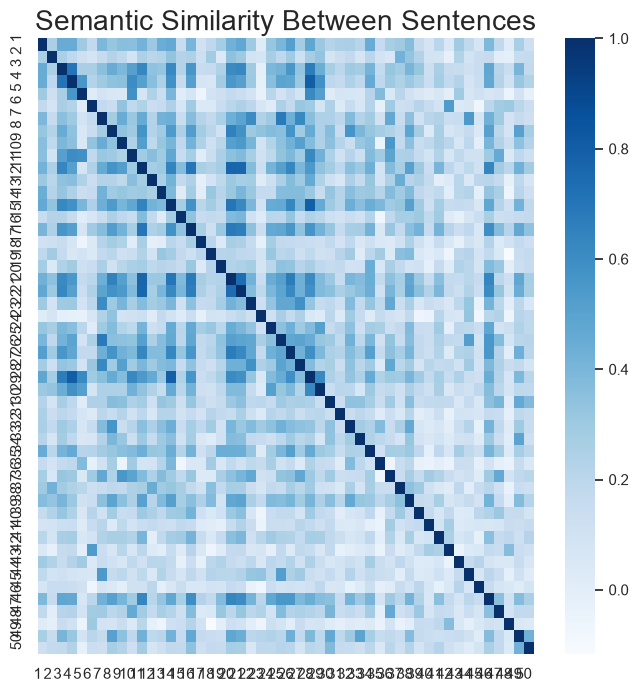

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 8))

sns.heatmap(similarity_matrix, cmap='Blues')

plt.xticks(range(len(texts)), range(1, len(texts) + 1))
plt.yticks(range(len(texts)), range(1, len(texts) + 1))
plt.title("Semantic Similarity Between Abstract", fontsize=20)


### Semantic search


In [49]:
documents = [
    "Companies invest in research and development to create new products.",
    "Government subsidies encourage firms to adopt renewable energy.",
    "Artificial intelligence can improve medical diagnosis.",
    "Women inventors face barriers in the patenting process.",
    "Universities contribute to technological innovation.",
    "Climate change is affecting agricultural productivity."
]

doc_embeddings = model.encode(documents)

query = "How does public funding support green technology?"

query_embedding = model.encode([query])

scores = cosine_similarity(
    query_embedding,
    doc_embeddings
)[0]

results = pd.DataFrame({
    "Document": documents,
    "Similarity": scores
}).sort_values("Similarity", ascending=False)

print(results.to_string(index=False))

                                                            Document  Similarity
     Government subsidies encourage firms to adopt renewable energy.    0.488883
Companies invest in research and development to create new products.    0.371668
                Universities contribute to technological innovation.    0.313298
              Climate change is affecting agricultural productivity.    0.300127
             Women inventors face barriers in the patenting process.    0.211563
              Artificial intelligence can improve medical diagnosis.   -0.045671
